Machine Learning

Progetto 2

Il dataset Linnerud presenta un problema di regressione Multi-Target (3 target

totali: Weight, Waist, Pulse).

Addestrare e confrontare alcuni modelli di regressione sul dataset, riducendo il

problema da Multi-Target a Single-Target tramite

1. PCA

2. selezione manuale di un singolo target

1 Data Exploration & Preprocessing

• Caricamento e Analisi del dataset e fornire un’analisi descrittiva iniziale

(i.e. df.describe())

• Standardization delle feature (X) per garantire che tutti gli attributi

abbiano media zero e deviazione standard unitaria

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.datasets import load_linnerud
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd

In [4]:
data = load_linnerud(as_frame=True)
x = data.data
y = data.target
df = data.frame
df.describe()

,Chins,Situps,Jumps,Weight,Waist,Pulse
count,20.000000,20.000000,20.00000,20.000000,20.000000,20.000000
mean,9.450000,145.550000,70.30000,178.600000,35.400000,56.100000
std,5.286278,62.566575,51.27747,24.690505,3.201973,7.210373
min,1.000000,50.000000,25.00000,138.000000,31.000000,46.000000
25%,4.750000,101.000000,39.50000,160.750000,33.000000,51.500000
50%,11.500000,122.500000,54.00000,176.000000,35.000000,55.000000
75%,13.250000,210.000000,85.25000,191.500000,37.000000,60.500000
max,17.000000,251.000000,250.00000,247.000000,46.000000,74.000000


In [13]:
scaler = StandardScaler()
y_std = scaler.fit_transform(y)
x_std = scaler.fit_transform(x)


2 Target Engineering

Trasformare il problema Multi-Target in due distinti problemi Single-Target da

confrontare:

• PCA (Target Composto)

– Applicare la PCA alla matrice dei target standardizzata e mantenere

PC1

• Manuale (Target Selezionato)

– Selezionare il target Waist dalla matrice dei target standardizzata

come singolo target rappresentativo

1

In [14]:
pca_target = PCA(n_components=2)
y_pca = pca_target.fit_transform(y_std)
pc1 = y_pca[:, 0]
pc2 = y_pca[:, 1]
print(y_pca)

[[ 0.81780452 -0.58220197]
 [ 0.8507056  -0.24984705]
 [ 0.80612641  0.67090907]
 [-0.87717135  0.52589423]
 [ 0.79689562 -1.22066043]
 [ 0.22012086  0.08614684]
 [ 1.40657367  0.6266703 ]
 [-0.82982855  0.22924815]
 [-2.03812801  1.85280993]
 [-1.14496499 -0.54014271]
 [-0.18141258 -1.03940481]
 [-0.58602147 -0.91429091]
 [-1.41552003  0.59149341]
 [ 4.36950026  1.06105327]
 [ 1.10926846 -1.07537962]
 [ 0.60350901  1.19735008]
 [ 0.38399813 -0.14609356]
 [-1.0321341  -1.11908645]
 [-0.97248506 -0.77482859]
 [-2.28683639  0.8203608 ]]


In [15]:
waist = y_std[:, 1]
print(waist)

[ 0.1922524   0.51267307  0.83309374 -0.12816827 -0.12816827  0.1922524
  0.83309374 -0.44858894 -1.40985094 -0.7690096  -0.44858894 -0.7690096
 -0.44858894  3.39645908  0.1922524   0.51267307  0.51267307 -1.08943027
 -0.7690096  -0.7690096 ]


3 Addestramento & Valutazione

Addestrare i tre modelli di regressione (Linear Regression, Ridge, Lasso) su

entrambi gli scenari di target ridotto con PCA e selezione manuale, utilizzando

il set di feature completo e standardizzato:

• Definire e inizializzare i tre modelli di regressione (Lineare, Ridge con

α = 1.0, Lasso con α = 0.1)

• Eseguire l’addestramento su tutto il dataset per entrambi gli scenari

• Valutare e memorizzare i risultati come Mean Squared Error e R2 Score

per ogni combinazione di modello e scenario

In [16]:
x = x_std
y_pca = y_pca[:, 0]
y_waist = y_std[:, 1]


model_linear_reg_pca = LinearRegression()
model_linear_reg_pca.fit(x, y_pca)
print("Linear Regression Coefficients (PCA):", model_linear_reg_pca.coef_)

model_linear_reg_waist = LinearRegression()
model_linear_reg_waist.fit(x, y_waist)
print("Linear Regression Coefficients (Waist):", model_linear_reg_waist.coef_)

model_linear_reg_ridge_pca = LinearRegression()
model_linear_reg_ridge_pca.fit(x, y_pca)
model_ridge_pca = Ridge(alpha=1.0)
model_ridge_pca.fit(x, y_pca)
print("Ridge Coefficients (PCA):", model_ridge_pca.coef_)

model_ridge_waist = Ridge(alpha=1.0)
model_ridge_waist.fit(x, y_waist)
print("Ridge Coefficients (Waist):", model_ridge_waist.coef_)

model_lasso_pca = Lasso(alpha=0.1)
model_lasso_pca.fit(x, y_pca)
print("Lasso Coefficients (PCA):", model_lasso_pca.coef_)
print("Intercept (PCA):", model_lasso_pca.intercept_)

model_lasso_waist = Lasso(alpha=0.1)
model_lasso_waist.fit(x, y_waist)
print("Lasso Coefficients (Waist):", model_lasso_waist.coef_)
print("Intercept (Waist):", model_lasso_waist.intercept_)


Linear Regression Coefficients (PCA): [-0.21063241 -1.01281087  0.49918489]
Linear Regression Coefficients (Waist): [-0.22596508 -0.7881779   0.44797856]
Ridge Coefficients (PCA): [-0.24179375 -0.88709589  0.41000401]
Ridge Coefficients (Waist): [-0.24448099 -0.6907965   0.37332361]
Lasso Coefficients (PCA): [-0.13375697 -0.76119416  0.19268968]
Intercept (PCA): -3.6429122373530996e-17
Lasso Coefficients (Waist): [-0.14908429 -0.53656093  0.14148052]
Intercept (Waist): 3.496977032313065e-16


In [17]:
mse_linear_pca = mean_squared_error(y_pca, model_linear_reg_pca.predict(x))
mse_linear_waist = mean_squared_error(y_waist, model_linear_reg_waist.predict(x))
mse_ridge_pca = mean_squared_error(y_pca, model_ridge_pca.predict(x))
mse_ridge_waist = mean_squared_error(y_waist, model_ridge_waist.predict(x))
mse_lasso_pca = mean_squared_error(y_pca, model_lasso_pca.predict(x))
mse_lasso_waist = mean_squared_error(y_waist, model_lasso_waist.predict(x))
r2_linear_pca = r2_score(y_pca, model_linear_reg_pca.predict(x))
r2_linear_waist = r2_score(y_waist, model_linear_reg_waist.predict(x))
r2_ridge_pca = r2_score(y_pca, model_ridge_pca.predict(x))
r2_ridge_waist = r2_score(y_waist, model_ridge_waist.predict(x))
r2_lasso_pca = r2_score(y_pca, model_lasso_pca.predict(x))
r2_lasso_waist = r2_score(y_waist, model_lasso_waist.predict(x))

print(f"Linear Regression MSE (PCA): {mse_linear_pca:.4f}")
print(f"Linear Regression MSE (Waist): {mse_linear_waist:.4f}")
print(f"Ridge MSE (PCA): {mse_ridge_pca:.4f}")
print(f"Ridge MSE (Waist): {mse_ridge_waist:.4f}")
print(f"Lasso MSE (PCA): {mse_lasso_pca:.4f}")
print(f"Lasso MSE (Waist): {mse_lasso_waist:.4f}")

print(f"Linear Regression R2 (PCA): {r2_linear_pca:.4f}")
print(f"Linear Regression R2 (Waist): {r2_linear_waist:.4f}")
print(f"Ridge R2 (PCA): {r2_ridge_pca:.4f}")
print(f"Ridge R2 (Waist): {r2_ridge_waist:.4f}")
print(f"Lasso R2 (PCA): {r2_lasso_pca:.4f}")
print(f"Lasso R2 (Waist): {r2_lasso_waist:.4f}")

Linear Regression MSE (PCA): 1.2689
Linear Regression MSE (Waist): 0.4522
Ridge MSE (PCA): 1.2759
Ridge MSE (Waist): 0.4567
Lasso MSE (PCA): 1.3324
Lasso MSE (Waist): 0.5157
Linear Regression R2 (PCA): 0.3970
Linear Regression R2 (Waist): 0.5478
Ridge R2 (PCA): 0.3936
Ridge R2 (Waist): 0.5433
Lasso R2 (PCA): 0.3668
Lasso R2 (Waist): 0.4843


4 Analisi & Visualizzazione

• Applicare la PCA al set di feature standardizzato e mantenere le due

componenti principali PC1 e PC2 per la visualizzazione 2D

• Creare un grafico di dispersione in cui:

– L’asse X `e il PC1 delle Feature

– L’asse Y `e la PCA con n components=1

– Tracciare le tre rette di regressione (Lineare, Ridge, Lasso) ri-addestrate

sulla sola PC1 delle Feature, includendo il loro rispettivo R2 Score

finale nell’etichetta

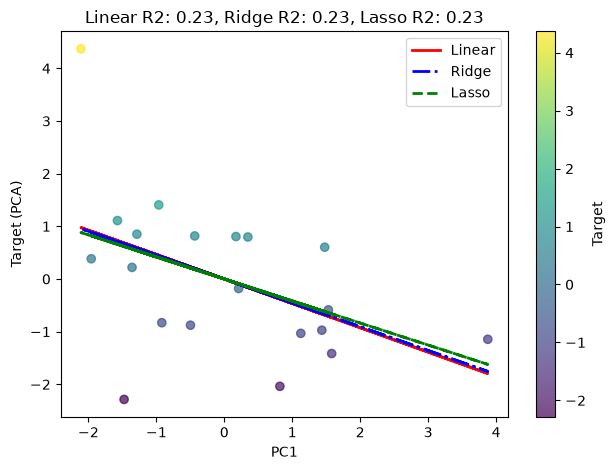

In [28]:
x_pca = PCA(n_components=2).fit_transform(x_std)
pc1_features = x_pca[:, 0]

pca_target = PCA(n_components=1)
y_pca = pca_target.fit_transform(y_std)

plt.scatter(pc1_features, y_pca, c=y_pca, cmap="viridis", alpha=0.7)
plt.xlabel('PC1')
plt.ylabel('Target (PCA)')
plt.colorbar(label='Target')

x_plot = pc1_features.reshape(-1, 1)
y_plot = y_pca

model_linear_reg_pca = LinearRegression()
model_linear_reg_pca.fit(x_plot, y_plot)
y_pred = model_linear_reg_pca.predict(x_plot)
r2 = r2_score(y_plot, y_pred)
plt.plot(x_plot, y_pred, color='red', linewidth=2, linestyle='-', label='Linear')

model_ridge_pca = Ridge(alpha=1.0)
model_ridge_pca.fit(x_plot, y_plot)
y_pred_ridge = model_ridge_pca.predict(x_plot)
r2_ridge = r2_score(y_plot, y_pred_ridge)
plt.plot(x_plot, y_pred_ridge, color='blue', linewidth=2, linestyle='-.', label='Ridge')

model_lasso_pca = Lasso(alpha=0.1)
model_lasso_pca.fit(x_plot, y_plot)
y_pred_lasso = model_lasso_pca.predict(x_plot)
r2_lasso = r2_score(y_plot, y_pred_lasso)
plt.plot(x_plot, y_pred_lasso, color='green', linewidth=2, linestyle='--', label='Lasso')
plt.title(f'Linear R2: {r2:.2f}, Ridge R2: {r2_ridge:.2f}, Lasso R2: {r2_lasso:.2f}')
plt.tight_layout()
plt.legend(loc='best')
plt.show()